# 03 · Evaluation and Explainability

Main models are evaluated across three training seeds (mean ± standard deviation). Figures that show single examples use the seed-42 models.

| Section | Question |
|---|---|
| 1 | How accurate is each model on each test set? |
| 2 | How do the results compare with Jiang (2024)? |
| 3 | Is the CNN vs ViT difference statistically significant, and is it consistent across seeds? |
| 4 | What kinds of errors do the models make? |
| 5 | Does blur and JPEG augmentation make the models more robust? |
| 6 | How do the models degrade under blur and JPEG compression? |
| 7 | Which image regions drive the predictions (Grad-CAM)? |
| 8 | How are the P(fake) scores distributed? |
| 9 | Can a recalibrated cut-off recover accuracy on new generators? |
| 10 | Are some object classes harder to detect? |
| 11 | What do the most confident mistakes look like? |
| 12 | Summary of key results |

**Outputs:** tables in `outputs/results/`, figures in `outputs/figures/`.

In [ ]:
# Environment setup
%pip install -q -U timm grad-cam

import io
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from PIL import Image
from scipy.stats import binomtest
from sklearn.metrics import confusion_matrix, f1_score, precision_score, roc_auc_score
from torchvision.transforms.functional import gaussian_blur
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from IPython.display import Markdown, display
from google.colab import drive

# Colab's local disk is wiped when the session ends, so all outputs live in Google Drive
drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/MAAI901_AIImageDetector")

DATA_DIR = PROJECT_DIR / "outputs" / "data"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"
for folder in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
REAL, FAKE = 0, 1                      # FAKE is the positive class (the detection target)
LABEL_NAMES = {REAL: "REAL", FAKE: "FAKE"}
TRAIN_SETUPS = ("trainSD14", "trainSD21")
TEST_SETS = {                          # split name -> generator behind the fake images
    "test_sd14": "SD 1.4",
    "test_sd21": "SD 2.1",
    "test_sd30": "SD 3.0",
    "test_sd21blur": "SD 2.1 blurred",
}

# Two ImageNet-pretrained models of similar size (23.5M vs 21.7M parameters),
# so the comparison isolates architecture rather than capacity.
MODELS = {
    "resnet50": {"timm_id": "resnet50.a1_in1k", "family": "cnn",
                 "display_name": "ResNet-50 (CNN)", "lr": 1e-4, "timm_kwargs": {}},
    "vit_small": {"timm_id": "vit_small_patch16_224.augreg_in21k_ft_in1k", "family": "vit",
                  "display_name": "ViT-S/16 (Transformer)", "lr": 5e-5, "timm_kwargs": {}},
}
INPUT_SIZE = 224                       # resolution both backbones were pretrained at

SEEDS = (42, 1, 2)            # every main model is trained three times
AUG_SEEDS = (42,)             # augmented models are trained once


def run_name(setup, model_key, seed=42, augment=False):
    """File name of a training run. Seed-42 runs without augmentation keep the original names."""
    name = f"{setup}__{model_key}"
    if augment:
        name += "__aug"
    if seed != 42:
        name += f"__s{seed}"
    return name


# Order matters if a session is cut short: the augmented models come before the extra seeds
RUNS = ([(s, m, 42, False) for s in TRAIN_SETUPS for m in MODELS]
        + [(s, m, seed, True) for s in TRAIN_SETUPS for m in MODELS for seed in AUG_SEEDS]
        + [(s, m, seed, False) for seed in SEEDS if seed != 42 for s in TRAIN_SETUPS for m in MODELS])

N_BOOTSTRAP = 1_000                         # resamples for confidence intervals
BLUR_SIGMAS = (0.0, 0.5, 1.0, 1.5, 2.0, 3.0)
JPEG_QUALITIES = (100, 90, 75, 50, 30)
ROBUSTNESS_IMAGES = 4_000                   # balanced subset for the degradation sweep
GRADCAM_IMAGES = 400                        # images per model and test set for CAM statistics
PRED_DIR = RESULTS_DIR / "predictions"      # cached P(fake) scores, so re-runs are fast
PRED_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

# One fixed colour per model across every figure
MODEL_COLORS = {"resnet50": "#2a78d6", "vit_small": "#eb6834"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e4df",
    "axes.axisbelow": True, "axes.edgecolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
Device: Tesla T4


In [ ]:
class Detector(nn.Module):
    """Pretrained timm backbone with built-in preprocessing.

    Keeping the resize and normalisation inside the model guarantees that
    training, evaluation, Grad-CAM and the demo all preprocess identically.
    """

    def __init__(self, spec, input_size=INPUT_SIZE, pretrained=True):
        super().__init__()
        self.spec = dict(spec)
        self.family = spec["family"]
        self.input_size = input_size
        self.backbone = timm.create_model(spec["timm_id"], pretrained=pretrained,
                                          num_classes=2, **spec["timm_kwargs"])
        cfg = timm.data.resolve_model_data_config(self.backbone)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1), persistent=False)

    def preprocess(self, x):
        """Float NCHW in [0, 1] at any size -> normalised NCHW at input_size."""
        if x.shape[-2:] != (self.input_size, self.input_size):
            # 32x32 -> 224x224 on the GPU; bilinear interpolation adds no new detail
            x = F.interpolate(x, size=(self.input_size, self.input_size),
                              mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std

    def forward(self, x):
        return self.backbone(self.preprocess(x))


def to_float(x_uint8):
    """uint8 NHWC (storage format) -> float NCHW in [0, 1] (model format)."""
    return x_uint8.permute(0, 3, 1, 2).float().div(255.0)

def load_split(name):
    """Return (images uint8 [N, 32, 32, 3], labels int64 [N]) for a saved split."""
    with np.load(DATA_DIR / f"{name}.npz") as z:
        return z["x"], z["y"]


def load_run(run):
    """Rebuild a trained model from its checkpoint (architecture + fine-tuned weights)."""
    ckpt = torch.load(MODEL_DIR / f"{run_name(*run)}.pt", map_location="cpu", weights_only=False)
    model = Detector(ckpt["spec"], input_size=ckpt["input_size"], pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(device).eval()


@torch.no_grad()
def predict_proba(model, x_uint8, batch_size=512):
    """P(FAKE) for every image, in batches, with mixed precision on GPU."""
    model.eval()
    use_amp = device.type == "cuda"
    out = []
    for i in range(0, len(x_uint8), batch_size):
        xb = to_float(torch.from_numpy(x_uint8[i:i + batch_size]).to(device))
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out.append(model(xb).float().softmax(1)[:, FAKE].cpu())
    return torch.cat(out).numpy()


runs = [r for r in RUNS if (MODEL_DIR / f"{run_name(*r)}.pt").exists()]
missing = [run_name(*r) for r in RUNS if r not in runs]
all_models = {run: load_run(run) for run in runs}
test_sets = {name: load_split(name) for name in TEST_SETS}
names = {k: v["display_name"] for k, v in MODELS.items()}

# Seed-42 main models, used for the single-example figures
models = {(s, m): all_models[(s, m, 42, False)] for s in TRAIN_SETUPS for m in MODELS}
print(f"{len(runs)} trained models and {len(test_sets)} test sets loaded.")
if missing:
    print("Not trained yet (skipped):", ", ".join(missing))

16 trained models and 4 test sets loaded.


## 1 · Main results

| Metric | Meaning |
|---|---|
| `accuracy` | % of all test images classified correctly |
| `fake_acc` | % of AI-generated images detected (recall on FAKE, Jiang's "fake image accuracy") |
| `real_acc` | % of real photographs correctly classified as real |
| `false_accusation_rate` | % of real photographs wrongly flagged as AI-generated |
| `auroc` | threshold-independent ranking quality (100 = perfect separation) |

Each value is the mean ± standard deviation over the three training seeds. The seed-42 results with 95% bootstrap confidence intervals are saved in `metrics_seed42.csv`.

In [ ]:
def bootstrap_ci(correct, n_boot=N_BOOTSTRAP, seed=SEED):
    """95% percentile bootstrap interval for accuracy, resampling test images."""
    rng = np.random.default_rng(seed)
    c = correct.astype(np.float32)
    accs = np.concatenate([c[rng.integers(0, len(c), size=(100, len(c)))].mean(1)
                           for _ in range(n_boot // 100)])
    return np.quantile(accs, [0.025, 0.975])


def compute_metrics(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    lo, hi = bootstrap_ci(pred == y)
    return {"n": len(y), "accuracy": (pred == y).mean() * 100,
            "acc_ci_low": lo * 100, "acc_ci_high": hi * 100,
            "fake_acc": tp / max(1, tp + fn) * 100, "real_acc": tn / max(1, tn + fp) * 100,
            "precision_fake": precision_score(y, pred, zero_division=0) * 100,
            "f1_fake": f1_score(y, pred, zero_division=0) * 100,
            "auroc": roc_auc_score(y, p) * 100,
            "false_accusation_rate": fp / max(1, tn + fp) * 100,
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}


def cached_predictions(run, tname):
    f = PRED_DIR / f"{run_name(*run)}__{tname}.npy"
    x = test_sets[tname][0]
    if f.exists():
        p = np.load(f)
        if len(p) == len(x):
            return p
    p = predict_proba(all_models[run], x)
    np.save(f, p)
    return p


P, rows = {}, []
for run in runs:
    setup, m, seed, aug = run
    for tname, (x, y) in test_sets.items():
        P[(run, tname)] = p = cached_predictions(run, tname)
        rows.append({"setup": setup, "model": m, "seed": seed, "augment": aug, "test_set": tname,
                     **compute_metrics(y, p)})
metrics_all = pd.DataFrame(rows)
metrics_all.to_csv(RESULTS_DIR / "metrics_all_runs.csv", index=False)

# Seed-42 main models (used by the single-run figures) and the across-seed averages
probs = {(s, m, t): P[((s, m, 42, False), t)] for s in TRAIN_SETUPS for m in MODELS for t in TEST_SETS}
metrics = metrics_all[(metrics_all.seed == 42) & ~metrics_all.augment].drop(columns=["seed", "augment"])
metrics.to_csv(RESULTS_DIR / "metrics_seed42.csv", index=False)

KEY = ["accuracy", "fake_acc", "real_acc", "f1_fake", "auroc", "false_accusation_rate"]
main_runs = metrics_all[~metrics_all.augment]
grouped = main_runs.groupby(["setup", "model", "test_set"], sort=False)
metrics_mean = grouped[KEY].mean().reset_index()
metrics_std = grouped[KEY].std().reset_index()
metrics_mean["n_seeds"] = grouped.size().values
metrics_mean.to_csv(RESULTS_DIR / "metrics_mean_across_seeds.csv", index=False)
metrics_std.to_csv(RESULTS_DIR / "metrics_std_across_seeds.csv", index=False)

table = metrics_mean[["setup", "model", "test_set", "n_seeds"]].copy()
for col in KEY:
    table[col] = [f"{a:.2f} \u00b1 {b:.2f}" if b == b else f"{a:.2f}"
                  for a, b in zip(metrics_mean[col], metrics_std[col])]
table.assign(model=table.model.map(names)).set_index(["setup", "model", "test_set"])

n_seeds      accuracy  \
setup     model                  test_set                               
trainSD14 ResNet-50 (CNN)        test_sd14            3  95.19 ± 0.04   
                                 test_sd21            3  93.44 ± 0.05   
                                 test_sd30            3  90.12 ± 0.35   
                                 test_sd21blur        3  87.75 ± 3.76   
          ViT-S/16 (Transformer) test_sd14            3  97.94 ± 0.80   
                                 test_sd21            3  95.51 ± 0.29   
                                 test_sd30            3  89.44 ± 1.78   
                                 test_sd21blur        3  55.46 ± 5.30   
trainSD21 ResNet-50 (CNN)        test_sd14            3  81.01 ± 1.05   
                                 test_sd21            3  97.54 ± 0.11   
                                 test_sd30            3  75.34 ± 0.97   
                                 test_sd21blur        3  88.63 ± 3.09   
          ViT-S/16 (Transformer) test_sd14            3  83.00 ± 1.65   
                                 test_sd21            3  99.24 ± 0.06   
                                 test_sd30            3  71.25 ± 1.51   
                                 test_sd21blur        3  62.31 ± 8.81   

                                                     fake_acc      real_acc  \
setup     model                  test_set                                     
trainSD14 ResNet-50 (CNN)        test_sd14       95.45 ± 0.28  94.94 ± 0.33   
                                 test_sd21       91.94 ± 0.24  94.94 ± 0.33   
                                 test_sd30       85.31 ± 0.39  94.94 ± 0.33   
                                 test_sd21blur   80.55 ± 7.85  94.94 ± 0.33   
          ViT-S/16 (Transformer) test_sd14       97.85 ± 1.26  98.03 ± 0.36   
                                 test_sd21       92.99 ± 0.24  98.03 ± 0.36   
                                 test_sd30       80.84 ± 3.33  98.03 ± 0.36   
                                 test_sd21blur  12.89 ± 10.25  98.03 ± 0.36   
trainSD21 ResNet-50 (CNN)        test_sd14       64.33 ± 2.20  97.47 ± 0.12   
                                 test_sd21       97.60 ± 0.19  97.47 ± 0.12   
                                 test_sd30       53.21 ± 2.06  97.47 ± 0.12   
                                 test_sd21blur   79.79 ± 6.30  97.47 ± 0.12   
          ViT-S/16 (Transformer) test_sd14       66.47 ± 3.45  99.32 ± 0.14   
                                 test_sd21       99.16 ± 0.23  99.32 ± 0.14   
                                 test_sd30       43.19 ± 3.12  99.32 ± 0.14   
                                 test_sd21blur  25.30 ± 17.61  99.32 ± 0.14   

                                                      f1_fake         auroc  \
setup     model                  test_set                                     
trainSD14 ResNet-50 (CNN)        test_sd14       95.18 ± 0.03  99.02 ± 0.04   
                                 test_sd21       93.34 ± 0.04  98.30 ± 0.08   
                                 test_sd30       89.63 ± 0.37  97.16 ± 0.23   
                                 test_sd21blur   86.66 ± 4.76  96.43 ± 0.67   
          ViT-S/16 (Transformer) test_sd14       97.92 ± 0.82  99.79 ± 0.12   
                                 test_sd21       95.39 ± 0.29  99.37 ± 0.07   
                                 test_sd30       88.42 ± 2.13  98.20 ± 0.54   
                                 test_sd21blur  21.51 ± 16.15  91.07 ± 2.22   
trainSD21 ResNet-50 (CNN)        test_sd14       77.08 ± 1.59  94.77 ± 0.17   
                                 test_sd21       97.54 ± 0.11  99.69 ± 0.02   
                                 test_sd30       68.32 ± 1.69  90.18 ± 0.63   
                                 test_sd21blur   87.44 ± 3.79  98.13 ± 0.26   
          ViT-S/16 (Transformer) test_sd14       79.49 ± 2.43  98.04 ± 0.16   
                                 test_sd21       99.24 ± 0.06  99.97 ± 0.00   
                                 test_sd30    

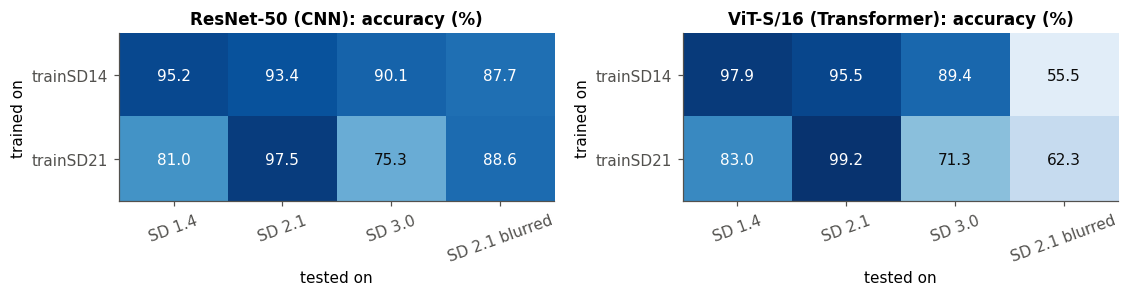

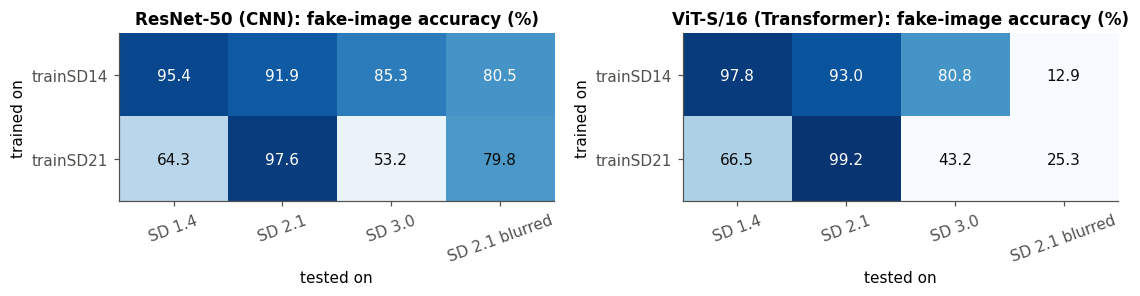

In [ ]:
def heatmaps(value, title):
    fig, axes = plt.subplots(1, len(MODELS), figsize=(5.2 * len(MODELS), 2.8), squeeze=False)
    for ax, m in zip(axes[0], MODELS):
        t = metrics_mean[metrics_mean.model == m].pivot(index="setup", columns="test_set", values=value)
        t = t[list(TEST_SETS)]
        ax.imshow(t.values, cmap="Blues", vmin=50, vmax=100, aspect="auto")
        ax.grid(False)
        ax.set_xticks(range(t.shape[1]), [TEST_SETS[c] for c in t.columns], rotation=20)
        ax.set_yticks(range(t.shape[0]), t.index)
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                v = t.values[i, j]
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v > 80 else INK)
        ax.set(title=f"{names[m]}: {title}", xlabel="tested on", ylabel="trained on")
    fig.tight_layout()
    return fig


for value, title, fname in [("accuracy", "accuracy (%)", "03_accuracy_heatmap"),
                            ("fake_acc", "fake-image accuracy (%)", "03_fake_accuracy_heatmap")]:
    fig = heatmaps(value, title)
    fig.savefig(FIG_DIR / f"{fname}.png")
    plt.show()

**What this shows.** On the generator each model was trained on, the ViT is more accurate in both setups (97.9% vs 95.2% and 99.2% vs 97.5%) and wrongly flags far fewer real photos (2.0% vs 5.1% and 0.7% vs 2.5%). On new generators the advantage disappears: the ViT is better on SD 2.1 after SD 1.4 training and on SD 1.4 after SD 2.1 training, but the CNN is better on SD 3.0 in both setups. On the blurred fakes the ViT collapses, detecting only 12.9% and 25.3% of them, with a large spread across seeds. The real-image accuracy is identical across the four test sets because they share the same real photographs; only the fakes change.

## 2 · Comparison with Jiang (2024)

Grey bars are the accuracies **reported by Jiang (2024)**: a two-layer CNN (Bird & Lotfi's architecture) and DenseNet-121, both trained from scratch at 32x32. The models here are pretrained and fine-tuned at 224x224, so this comparison gives context rather than a strict like-for-like benchmark. Error bars on my models show the standard deviation across the three seeds.

Note: Jiang's main SD 3.0 results use 512px generations, whereas the SD 3.0 test set here is the 1024px version.

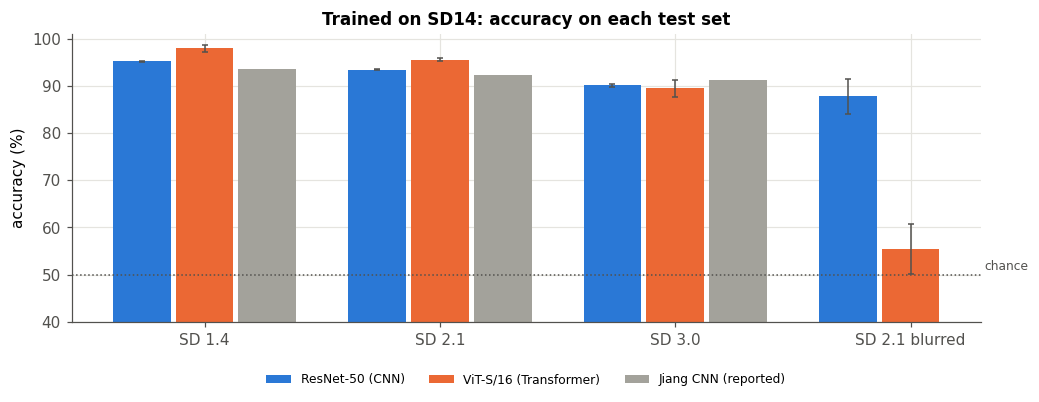

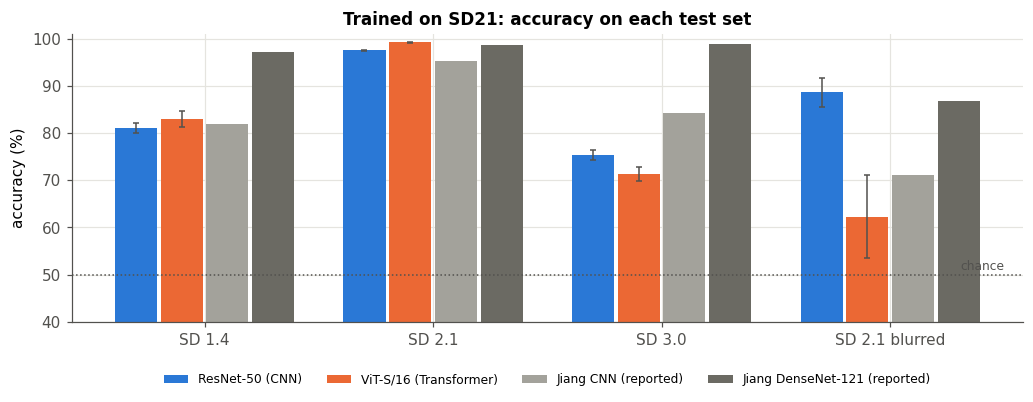

test_set                                 test_sd14  test_sd21  test_sd30  \
setup     model                                                            
trainSD14 Jiang CNN (reported)               93.67      92.30      91.21   
          ResNet-50 (CNN)                    95.19      93.44      90.12   
          ViT-S/16 (Transformer)             97.94      95.51      89.44   
trainSD21 Jiang CNN (reported)               81.89      95.23      84.30   
          Jiang DenseNet-121 (reported)      97.23      98.57      98.78   
          ResNet-50 (CNN)                    81.01      97.54      75.34   
          ViT-S/16 (Transformer)             83.00      99.24      71.25   

test_set                                 test_sd21blur  
setup     model                                         
trainSD14 Jiang CNN (reported)                     NaN  
          ResNet-50 (CNN)                        87.75  
          ViT-S/16 (Transformer)                 55.46  
trainSD21 Jiang CNN (reported)                   71.13  
          Jiang DenseNet-121 (reported)          86.88  
          ResNet-50 (CNN)                        88.63  
          ViT-S/16 (Transformer)                 62.31

In [ ]:
# Overall accuracy (%) reported by Jiang (2024), Tables 3, 4 and 9-10
JIANG = {
    ("trainSD14", "Jiang CNN"): {"test_sd14": 93.67, "test_sd21": 92.30, "test_sd30": 91.21},
    ("trainSD21", "Jiang CNN"): {"test_sd14": 81.89, "test_sd21": 95.23, "test_sd30": 84.30,
                                 "test_sd21blur": 71.13},
    ("trainSD21", "Jiang DenseNet-121"): {"test_sd14": 97.23, "test_sd21": 98.57,
                                          "test_sd30": 98.78, "test_sd21blur": 86.88},
}
REF_COLORS = {"Jiang CNN": "#a3a29b", "Jiang DenseNet-121": "#6b6a63"}

for setup in TRAIN_SETUPS:
    mean = metrics_mean[metrics_mean.setup == setup].set_index(["model", "test_set"])
    std = metrics_std[metrics_std.setup == setup].set_index(["model", "test_set"]).fillna(0)
    tests = list(TEST_SETS)
    series = [(names[m], MODEL_COLORS[m], [mean.loc[(m, t), "accuracy"] for t in tests],
               [std.loc[(m, t), "accuracy"] for t in tests]) for m in MODELS]
    series += [(f"{ref} (reported)", REF_COLORS[ref], [vals.get(t, np.nan) for t in tests], None)
               for (s, ref), vals in JIANG.items() if s == setup]
    width = 0.8 / len(series)
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    for k, (label, color, vals, err) in enumerate(series):
        xs = np.arange(len(tests)) + (k - (len(series) - 1) / 2) * width
        ax.bar(xs, vals, width * 0.92, color=color, label=label, yerr=err, capsize=2,
               error_kw={"elinewidth": 1, "ecolor": MUTED})
    ax.axhline(50, color=MUTED, lw=1, ls=":")
    ax.text(len(tests) - 0.5, 51, "chance", color=MUTED, ha="right", fontsize=8)
    ax.set_xticks(range(len(tests)), [TEST_SETS[t] for t in tests])
    ax.set(ylim=(40, 101), ylabel="accuracy (%)",
           title=f"Trained on {setup.replace('train', '')}: accuracy on each test set")
    ax.legend(ncol=len(series), fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14))
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"03_vs_jiang_{setup}.png")
    plt.show()

reference = pd.DataFrame([{"setup": s, "model": f"{m} (reported)", "test_set": t, "accuracy": v}
                          for (s, m), d in JIANG.items() for t, v in d.items()])
comparison = pd.concat([metrics_mean.assign(model=metrics_mean.model.map(names))
                        [["setup", "model", "test_set", "accuracy"]], reference])
comparison = comparison.pivot_table(index=["setup", "model"], columns="test_set",
                                    values="accuracy")[list(TEST_SETS)]
comparison.to_csv(RESULTS_DIR / "comparison_with_jiang.csv")
comparison.round(2)

**What this shows.** My CNN results are close to Jiang's CNN on the clean test sets, which suggests the pipeline is sound, and both studies find that training on SD 1.4 generalises better than training on SD 2.1. On the blurred set, my pretrained CNN is much more robust than Jiang's CNN (88.6% vs 71.1%). Jiang's DenseNet-121 is still clearly the best on unseen generators, especially SD 3.0 (98.8%).

## 3 · Statistical significance (McNemar's test)

Both models classify the same test images, so they are compared image by image. McNemar's exact test considers only the images on which exactly one model is correct; p < 0.05 indicates the difference is unlikely to be due to chance. The test is repeated for each seed, so a difference only counts as robust if it points the same way in all three.

In [ ]:
cnn, vit = list(MODELS)
rows = []
for setup in TRAIN_SETUPS:
    for seed in SEEDS:
        rc, rv = (setup, cnn, seed, False), (setup, vit, seed, False)
        if rc not in all_models or rv not in all_models:
            continue
        for tname, (_, y) in test_sets.items():
            cnn_ok = (P[(rc, tname)] >= 0.5) == y
            vit_ok = (P[(rv, tname)] >= 0.5) == y
            only_cnn, only_vit = int((cnn_ok & ~vit_ok).sum()), int((~cnn_ok & vit_ok).sum())
            n = only_cnn + only_vit
            p_value = binomtest(only_cnn, n, 0.5).pvalue if n else 1.0
            rows.append({"setup": setup, "seed": seed, "test_set": tname, "only CNN correct": only_cnn,
                         "only ViT correct": only_vit, "p_value": p_value,
                         "better model": "ViT" if only_vit > only_cnn else "CNN",
                         "significant (p < 0.05)": p_value < 0.05})
significance_all = pd.DataFrame(rows)
significance_all.to_csv(RESULTS_DIR / "significance_mcnemar_all_seeds.csv", index=False)
significance = significance_all[significance_all.seed == 42]

consistency = (significance_all.groupby(["setup", "test_set"], sort=False)
               .agg(seeds=("seed", "count"),
                    ViT_better_in=("better model", lambda w: int((w == "ViT").sum())),
                    significant_in=("significant (p < 0.05)", "sum"),
                    largest_p=("p_value", "max")))
consistency.to_csv(RESULTS_DIR / "significance_consistency.csv")
display(significance_all)
consistency

,setup,seed,test_set,only CNN correct,only ViT correct,p_value,better model,significant (p < 0.05)
0,trainSD14,42,test_sd14,120,758,5.772838e-114,ViT,True
1,trainSD14,42,test_sd21,464,898,2.585827e-32,ViT,True
2,trainSD14,42,test_sd30,849,1118,1.431693e-09,ViT,True
3,trainSD14,42,test_sd21blur,7396,522,0.000000e+00,CNN,True
4,trainSD14,1,test_sd14,111,740,8.144042e-115,ViT,True
5,trainSD14,1,test_sd21,406,863,2.526855e-38,ViT,True
6,trainSD14,1,test_sd30,1154,897,1.514921e-08,CNN,True
7,trainSD14,1,test_sd21blur,5181,619,0.000000e+00,CNN,True
8,trainSD14,2,test_sd14,283,653,2.266112e-34,ViT,True
9,trainSD14,2,test_sd21,460,811,5.057529e-23,ViT,True


seeds  ViT_better_in  significant_in     largest_p
setup     test_set                                                         
trainSD14 test_sd14          3              3               3  2.266112e-34
          test_sd21          3              3               3  5.057529e-23
          test_sd30          3              1               3  1.514921e-08
          test_sd21blur      3              0               3  0.000000e+00
trainSD21 test_sd14          3              2               2  2.457950e-01
          test_sd21          3              3               3  1.135671e-50
          test_sd30          3              0               3  4.161064e-44
          test_sd21blur      3              0               3  0.000000e+00

**What this shows.** Every difference is significant except one (SD 2.1 training tested on SD 1.4, seed 1). The direction is consistent across seeds for the in-domain test sets and SD 2.1 (ViT better), for SD 3.0 after SD 2.1 training and for the blurred sets (CNN better). The two mixed cases are SD 3.0 after SD 1.4 training (ViT better in one seed out of three) and SD 1.4 after SD 2.1 training (ViT better in two).

## 4 · Confusion matrices (seed 42; rows: true label, columns: predicted label)

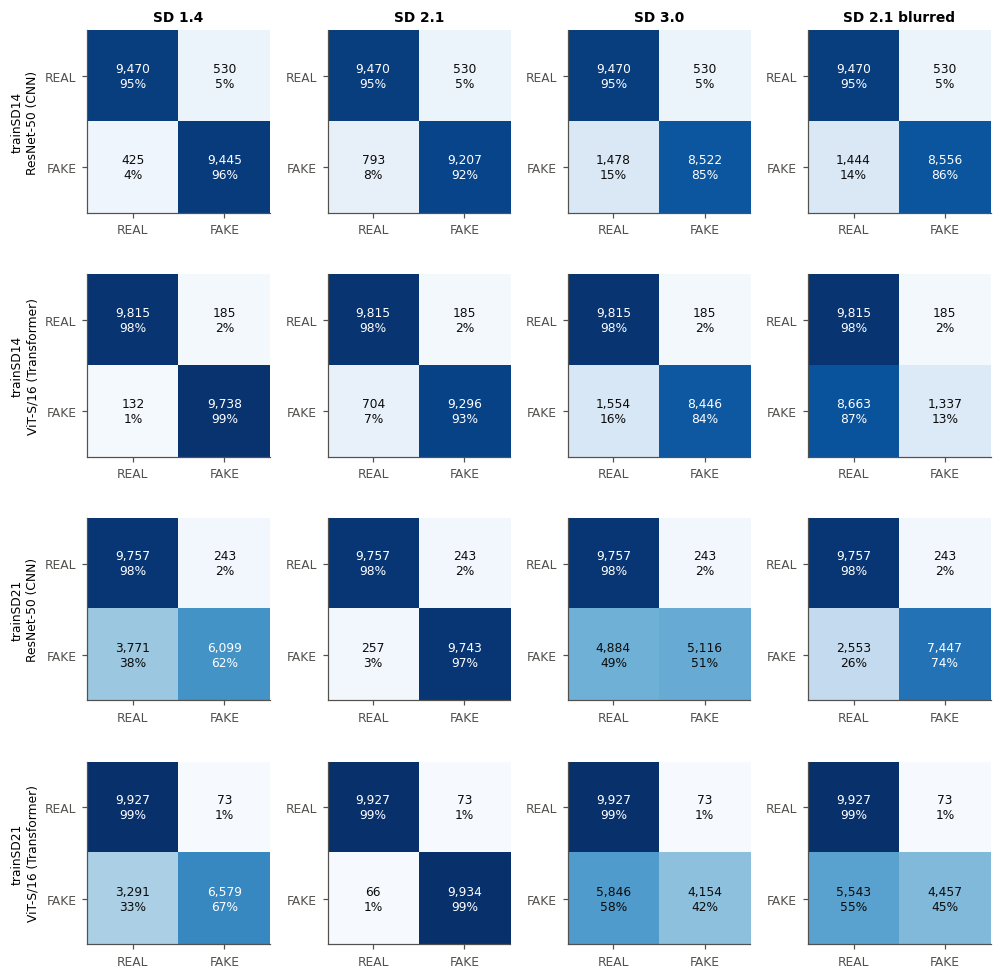

In [ ]:
groups = list(metrics.groupby(["setup", "model"], sort=False))
fig, axes = plt.subplots(len(groups), len(TEST_SETS), figsize=(2.3 * len(TEST_SETS), 2.3 * len(groups)),
                         squeeze=False)
for r, ((setup, m), g) in enumerate(groups):
    for c, t in enumerate(TEST_SETS):
        row = g[g.test_set == t].iloc[0]
        cm = np.array([[row.tn, row.fp], [row.fn, row.tp]])
        share = cm / cm.sum(1, keepdims=True)
        ax = axes[r, c]
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        ax.grid(False)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center",
                        fontsize=8, color="white" if share[i, j] > 0.6 else INK)
        ax.set_xticks([0, 1], ["REAL", "FAKE"], fontsize=8)
        ax.set_yticks([0, 1], ["REAL", "FAKE"], fontsize=8)
        if r == 0:
            ax.set_title(TEST_SETS[t], fontsize=9)
        if c == 0:
            ax.set_ylabel(f"{setup}\n{names[m]}", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_confusion_matrices.png")
plt.show()

**What this shows.** The CNN trained on SD 2.1 misses many SD 1.4 and SD 3.0 fakes (38% and 49%), and the ViT trained on SD 1.4 labels 87% of the blurred fakes as real. In both cases the errors are almost all in one direction: fakes classified as real, while the real photographs are still recognised correctly.

## 5 · Effect of blur and JPEG augmentation

Wang et al. (2020) found that training with random blur and JPEG compression makes fake-image detectors more robust. Here each augmented model (seed 42) is compared with the average of the three main models. The most important columns are the blurred test set, where the main ViT struggled, and the in-domain test set, to check that augmentation does not cost accuracy on clean images.

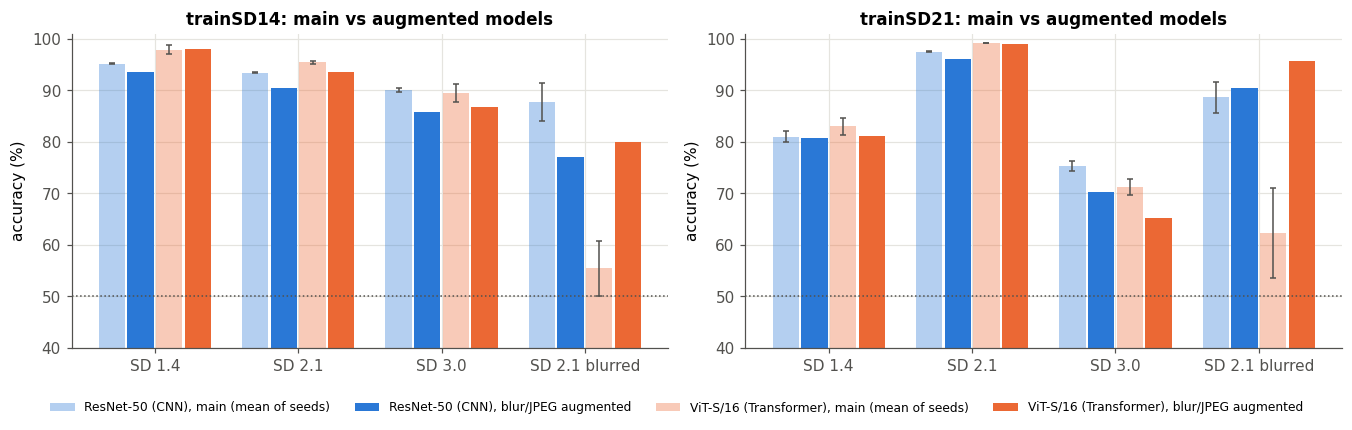

acc_main  acc_main_std  \
setup     model                  test_set                                
trainSD14 ResNet-50 (CNN)        test_sd14         95.19          0.04   
                                 test_sd21         93.44          0.05   
                                 test_sd30         90.12          0.35   
                                 test_sd21blur     87.75          3.76   
          ViT-S/16 (Transformer) test_sd14         97.94          0.80   
                                 test_sd21         95.51          0.29   
                                 test_sd30         89.44          1.78   
                                 test_sd21blur     55.46          5.30   
trainSD21 ResNet-50 (CNN)        test_sd14         81.01          1.05   
                                 test_sd21         97.54          0.11   
                                 test_sd30         75.34          0.97   
                                 test_sd21blur     88.63          3.09   
          ViT-S/16 (Transformer) test_sd14         83.00          1.65   
                                 test_sd21         99.24          0.06   
                                 test_sd30         71.25          1.51   
                                 test_sd21blur     62.31          8.81   

                                                acc_augmented  change  \
setup     model                  test_set                               
trainSD14 ResNet-50 (CNN)        test_sd14              93.61   -1.58   
                                 test_sd21              90.52   -2.92   
                                 test_sd30              85.81   -4.31   
                                 test_sd21blur          77.08  -10.67   
          ViT-S/16 (Transformer) test_sd14              98.05    0.11   
                                 test_sd21              93.66   -1.84   
                                 test_sd30              86.70   -2.74   
                                 test_sd21blur          79.97   24.52   
trainSD21 ResNet-50 (CNN)        test_sd14              80.74   -0.26   
                                 test_sd21              96.16   -1.38   
                                 test_sd30              70.36   -4.98   
                                 test_sd21blur          90.54    1.91   
          ViT-S/16 (Transformer) test_sd14              81.07   -1.93   
                                 test_sd21              98.96   -0.27   
                                 test_sd30              65.16   -6.09   
                                 test_sd21blur          95.75   33.44   

                                                fake_acc_main  \
setup     model                  test_set                       
trainSD14 ResNet-50 (CNN)        test_sd14              95.45   
                                 test_sd21              91.94   
                                 test_sd30              85.31   
                                 test_sd21blur          80.55   
          ViT-S/16 (Transformer) test_sd14              97.85   
                                 test_sd21              92.99   
                                 test_sd30              80.84   
                                 test_sd21blur          12.89   
trainSD21 ResNet-50 (CNN)        test_sd14              64.33   
                                 test_sd21              97.60   
                                 test_sd30              53.21   
                                 test_sd21blur          79.79   
          ViT-S/16 (Transformer) test_sd14              66.47   
                                 test_sd21              99.16   
                                 test_sd30              43.19   
                                 test_sd21blur          25.30   

                                                fake_acc_augmented  \
setup     model                  test_set                            
trainSD14 ResNet-50 (CNN)        test_sd14                   94.93   
                   

In [ ]:
aug_runs = [r for r in runs if r[3]]
if not aug_runs:
    print("No augmented models found - train them in notebook 02 first.")
else:
    rows = []
    for (setup, m, seed, _) in aug_runs:
        for tname, (_, y) in test_sets.items():
            a = metrics_all[(metrics_all.setup == setup) & (metrics_all.model == m) & metrics_all.augment
                            & (metrics_all.seed == seed) & (metrics_all.test_set == tname)].iloc[0]
            b = metrics_mean[(metrics_mean.setup == setup) & (metrics_mean.model == m)
                             & (metrics_mean.test_set == tname)].iloc[0]
            s = metrics_std[(metrics_std.setup == setup) & (metrics_std.model == m)
                            & (metrics_std.test_set == tname)].iloc[0]
            rows.append({"setup": setup, "model": m, "test_set": tname,
                         "acc_main": b.accuracy, "acc_main_std": s.accuracy, "acc_augmented": a.accuracy,
                         "change": a.accuracy - b.accuracy,
                         "fake_acc_main": b.fake_acc, "fake_acc_augmented": a.fake_acc,
                         "auroc_main": b.auroc, "auroc_augmented": a.auroc})
    augmentation = pd.DataFrame(rows)
    augmentation.to_csv(RESULTS_DIR / "augmentation_effect.csv", index=False)

    fig, axes = plt.subplots(1, len(TRAIN_SETUPS), figsize=(6.2 * len(TRAIN_SETUPS), 3.6), squeeze=False)
    width = 0.2
    for ax, setup in zip(axes[0], TRAIN_SETUPS):
        d = augmentation[augmentation.setup == setup].set_index(["model", "test_set"])
        for k, m in enumerate(MODELS):
            if (m, list(TEST_SETS)[0]) not in d.index:
                continue
            for j, (col, alpha, err) in enumerate((("acc_main", 0.35, "acc_main_std"), ("acc_augmented", 1.0, None))):
                xs = np.arange(len(TEST_SETS)) + (2 * k + j - 1.5) * width
                ax.bar(xs, [d.loc[(m, t), col] for t in TEST_SETS], width * 0.92, color=MODEL_COLORS[m],
                       alpha=alpha, yerr=None if err is None else [d.loc[(m, t), err] for t in TEST_SETS],
                       capsize=2, error_kw={"elinewidth": 1, "ecolor": MUTED},
                       label=f"{names[m]}, {'main (mean of seeds)' if j == 0 else 'blur/JPEG augmented'}")
        ax.axhline(50, color=MUTED, ls=":", lw=1)
        ax.set_xticks(range(len(TEST_SETS)), [TEST_SETS[t] for t in TEST_SETS])
        ax.set(ylim=(40, 101), ylabel="accuracy (%)", title=f"{setup}: main vs augmented models")
    fig.tight_layout()
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
    fig.savefig(FIG_DIR / "03_augmentation_effect.png")
    plt.show()
    display(augmentation.assign(model=augmentation.model.map(names))
            .set_index(["setup", "model", "test_set"]).round(2))

**What this shows.** Blur and JPEG augmentation fixes the ViT's weakness on blurred fakes (55.5% to 80.0% after SD 1.4 training, and 62.3% to 95.8% after SD 2.1 training, which is higher than Jiang's DenseNet). The cost is generalisation to the newest generator: every augmented model is less accurate on SD 3.0 (by 2.7 to 6.1 points). For the CNN trained on SD 1.4, augmentation even lowered accuracy on the blurred set. Augmentation therefore trades one kind of robustness for another rather than solving the problem.

## 6 · Robustness to image degradation

A controlled extension of Jiang's blur experiment: Gaussian blur or JPEG compression is applied equally to **real and fake** images, as happens when images are re-shared online. Each setup is evaluated on its in-domain test set, using a fixed, class-balanced subset. Solid lines are the seed-42 main models; dashed lines are the augmented models.

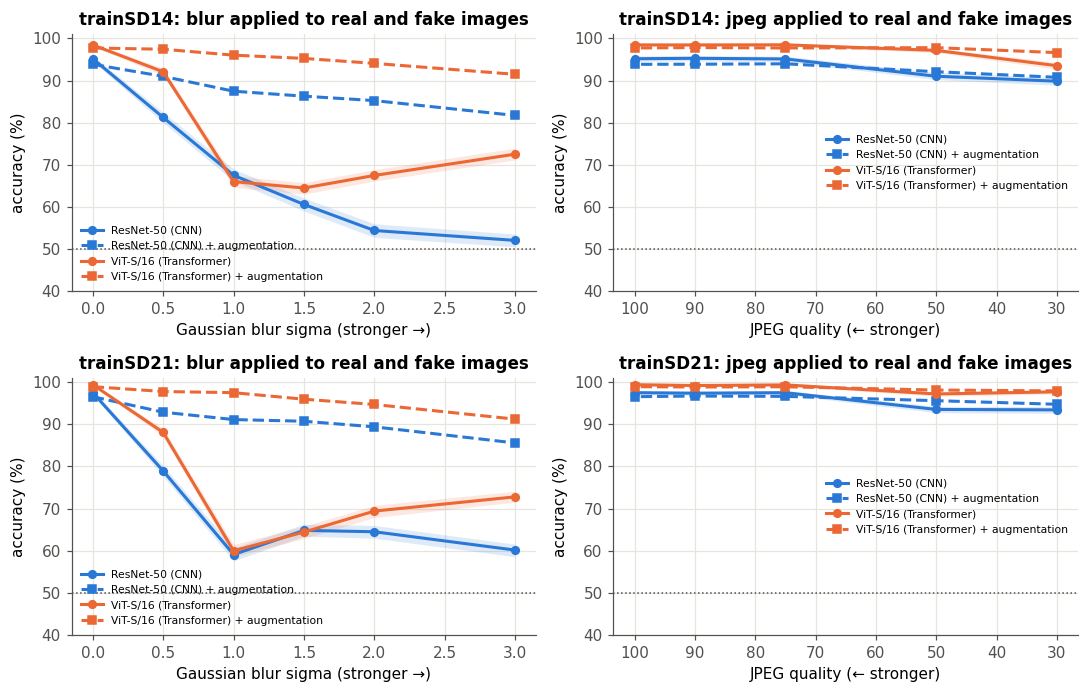

corruption                   blur                                jpeg        \
level                       0.0   0.5   1.0   1.5   2.0   3.0   30.0  50.0    
setup     model     augment                                                   
trainSD14 resnet50  False    95.2  81.2  67.6  60.6  54.4  52.1  89.8  91.0   
                    True     93.8  91.0  87.5  86.3  85.2  81.7  90.8  92.1   
          vit_small False    98.4  92.1  66.0  64.5  67.5  72.6  93.5  97.2   
                    True     97.7  97.4  96.0  95.2  94.1  91.5  96.6  97.8   
trainSD21 resnet50  False    97.5  79.0  59.1  64.8  64.5  60.2  93.4  93.5   
                    True     96.6  92.9  91.1  90.7  89.4  85.6  94.8  95.6   
          vit_small False    99.4  88.1  60.0  64.4  69.4  72.8  97.7  97.2   
                    True     98.9  97.8  97.5  96.0  94.7  91.2  97.9  98.1   

corruption                                     
level                       75.0  90.0  100.0  
setup     model     augment                    
trainSD14 resnet50  False    95.1  95.3  95.2  
                    True     94.0  93.9  93.8  
          vit_small False    98.5  98.4  98.4  
                    True     97.7  97.8  97.7  
trainSD21 resnet50  False    97.5  97.4  97.5  
                    True     96.6  96.7  96.6  
          vit_small False    99.4  99.2  99.4  
                    True     98.9  98.9  98.9

In [ ]:
def blur(x, sigma):
    if sigma <= 0:
        return x
    k = 2 * int(np.ceil(3 * sigma)) + 1            # kernel covers +/- 3 sigma
    t = torch.from_numpy(x).permute(0, 3, 1, 2).float()
    t = gaussian_blur(t, kernel_size=[k, k], sigma=[sigma, sigma])
    return t.round().clamp(0, 255).byte().permute(0, 2, 3, 1).numpy()


def jpeg(x, quality):
    if quality >= 100:
        return x
    out = np.empty_like(x)
    for i, img in enumerate(x):
        buf = io.BytesIO()
        Image.fromarray(img).save(buf, format="JPEG", quality=int(quality))
        out[i] = np.asarray(Image.open(buf).convert("RGB"))
    return out


in_domain = {"trainSD14": "test_sd14", "trainSD21": "test_sd21"}
rng = np.random.default_rng(SEED)
rows = []
for setup, tname in in_domain.items():
    x, y = test_sets[tname]
    idx = np.concatenate([rng.choice(np.where(y == lab)[0], min(ROBUSTNESS_IMAGES // 2, (y == lab).sum()),
                                     replace=False) for lab in (REAL, FAKE)])
    x, y = x[idx], y[idx]
    sweep_runs = [r for r in runs if r[0] == setup and r[2] == 42]
    conditions = ([("blur", s, blur(x, s)) for s in BLUR_SIGMAS]
                  + [("jpeg", q, jpeg(x, q)) for q in JPEG_QUALITIES])
    for kind, level, xc in conditions:
        for run in sweep_runs:
            rows.append({"setup": setup, "model": run[1], "augment": run[3], "corruption": kind, "level": level,
                         **compute_metrics(y, predict_proba(all_models[run], xc))})
robustness = pd.DataFrame(rows)
robustness.to_csv(RESULTS_DIR / "robustness_sweep.csv", index=False)

fig, axes = plt.subplots(len(TRAIN_SETUPS), 2, figsize=(10, 3.2 * len(TRAIN_SETUPS)), squeeze=False)
for r, setup in enumerate(TRAIN_SETUPS):
    for c, (kind, xlabel) in enumerate([("blur", "Gaussian blur sigma (stronger \u2192)"),
                                        ("jpeg", "JPEG quality (\u2190 stronger)")]):
        ax = axes[r, c]
        for m in MODELS:
            for aug, style in ((False, "-o"), (True, "--s")):
                g = robustness[(robustness.setup == setup) & (robustness.corruption == kind)
                               & (robustness.model == m) & (robustness.augment == aug)].sort_values("level")
                if g.empty:
                    continue
                ax.plot(g.level, g.accuracy, style, color=MODEL_COLORS[m], markersize=5,
                        label=names[m] + (" + augmentation" if aug else ""))
                if not aug:
                    ax.fill_between(g.level, g.acc_ci_low, g.acc_ci_high, color=MODEL_COLORS[m], alpha=0.15, lw=0)
        if kind == "jpeg":
            ax.invert_xaxis()
        ax.axhline(50, color=MUTED, lw=1, ls=":")
        ax.set(ylim=(40, 101), xlabel=xlabel, ylabel="accuracy (%)",
               title=f"{setup}: {kind} applied to real and fake images")
        ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_robustness.png")
plt.show()
robustness.pivot_table(index=["setup", "model", "augment"], columns=["corruption", "level"],
                       values="accuracy").round(1)

**What this shows.** When real and fake images are blurred equally, all main models fall sharply by σ = 1. At stronger blur the CNNs stay close to chance (52 to 60% at σ = 3), while the ViTs recover to about 73%. The augmented models stay above 80% at every blur level, and the augmented ViTs remain above 91%. JPEG compression barely affects any model, and the ViTs stay 2 to 4 points ahead.

## 7 · Explainability with Grad-CAM

Grad-CAM highlights the image regions that pushed a model towards its prediction. Bird & Lotfi (2024) found that their CNN largely ignored the main object and attended to small background imperfections. The figures below test whether the same holds for the fine-tuned CNN and the ViT (seed-42 models).

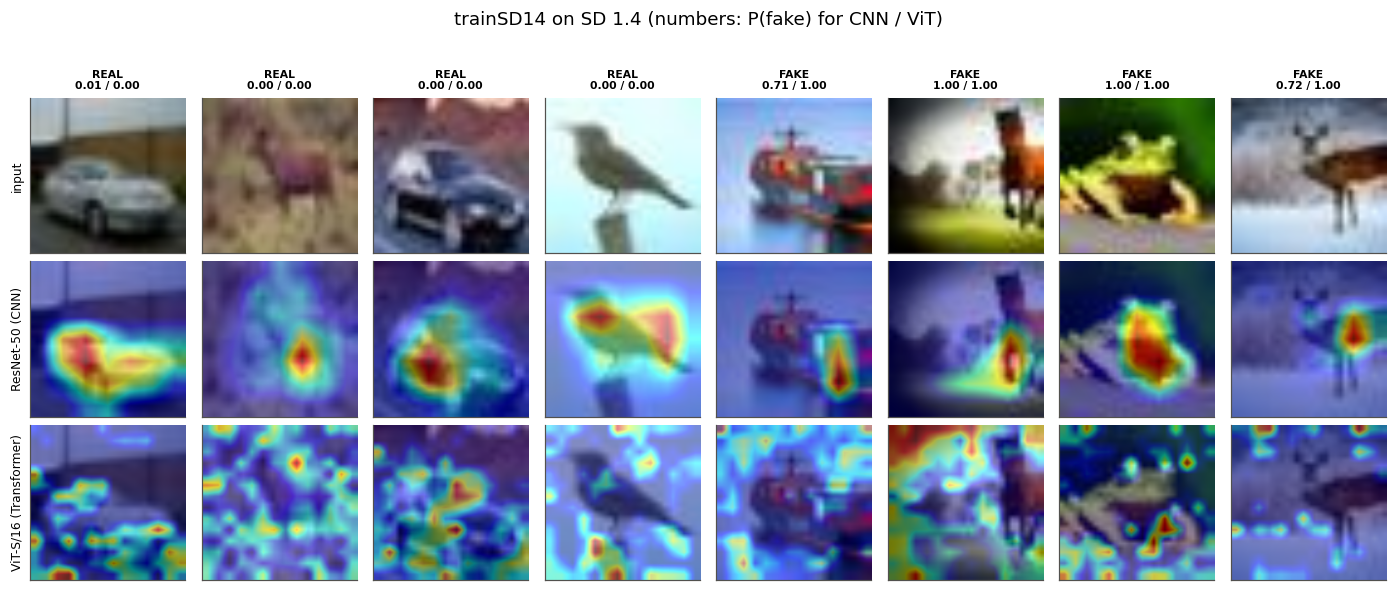

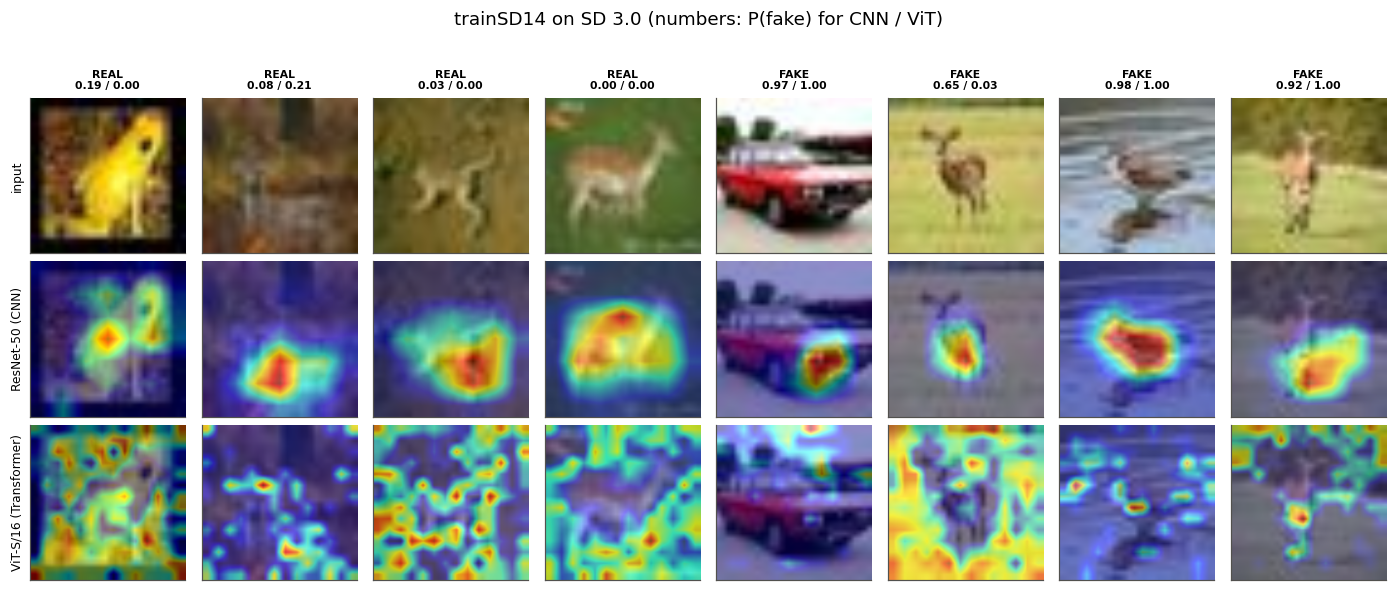

In [ ]:
def gradcam_layer(model):
    """Last spatial feature layer: final ResNet stage, or the last ViT block."""
    if model.family == "vit":
        return [model.backbone.blocks[-1].norm1]
    return [model.backbone.layer4[-1]]


def vit_reshape(model):
    """ViT outputs a token sequence; Grad-CAM needs a 2D map (14x14 patch grid)."""
    n_prefix = getattr(model.backbone, "num_prefix_tokens", 1)
    gh, gw = model.backbone.patch_embed.grid_size
    def reshape(tokens):
        tokens = tokens[:, n_prefix:, :]             # drop the [CLS] token
        return tokens.reshape(tokens.size(0), gh, gw, tokens.size(2)).permute(0, 3, 1, 2)
    return reshape


def gradcam(model, x_uint8, target_class=None, batch_size=32):
    """Heatmaps [N, 224, 224] in 0..1 and the matching upsampled images [N, 224, 224, 3].

    target_class=None explains whichever class the model predicted.
    """
    reshape = vit_reshape(model) if model.family == "vit" else None
    cams, imgs = [], []
    with GradCAM(model=model, target_layers=gradcam_layer(model),
                 reshape_transform=reshape) as cam:
        for i in range(0, len(x_uint8), batch_size):
            xb = to_float(torch.from_numpy(x_uint8[i:i + batch_size]).to(device))
            xb = F.interpolate(xb, size=(model.input_size, model.input_size),
                               mode="bilinear", align_corners=False)
            targets = (None if target_class is None
                       else [ClassifierOutputTarget(target_class)] * len(xb))
            cams.append(cam(input_tensor=xb, targets=targets))
            imgs.append(xb.permute(0, 2, 3, 1).cpu().numpy())
    return np.concatenate(cams), np.clip(np.concatenate(imgs), 0, 1)


def overlay(img01, cam, alpha=0.45):
    return show_cam_on_image(img01.astype(np.float32), cam, use_rgb=True, image_weight=1 - alpha)


for setup, tname in [("trainSD14", "test_sd14"), ("trainSD14", "test_sd30")]:
    x, y = test_sets[tname]
    idx = np.concatenate([rng.choice(np.where(y == lab)[0], 4, replace=False) for lab in (REAL, FAKE)])
    overlays = {}
    for m in MODELS:
        cams, imgs = gradcam(models[(setup, m)], x[idx])
        overlays[m] = [overlay(i, c) for i, c in zip(imgs, cams)]
    fig, axes = plt.subplots(1 + len(MODELS), len(idx), figsize=(1.6 * len(idx), 1.75 * (1 + len(MODELS))))
    for j, i in enumerate(idx):
        p = " / ".join(f"{probs[(setup, m, tname)][i]:.2f}" for m in MODELS)
        axes[0, j].imshow(imgs[j])
        axes[0, j].set_title(f"{LABEL_NAMES[y[i]]}\n{p}", fontsize=7)
        for r, m in enumerate(MODELS, start=1):
            axes[r, j].imshow(overlays[m][j])
        for r in range(1 + len(MODELS)):
            axes[r, j].set_xticks([]); axes[r, j].set_yticks([]); axes[r, j].grid(False)
    axes[0, 0].set_ylabel("input", fontsize=8)
    for r, m in enumerate(MODELS, start=1):
        axes[r, 0].set_ylabel(names[m], fontsize=8)
    fig.suptitle(f"{setup} on {TEST_SETS[tname]} (numbers: P(fake) for CNN / ViT)", y=1.02)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"03_gradcam_{setup}_{tname}.png")
    plt.show()

### Quantifying attention

For each model and class, the share of Grad-CAM heat that falls inside the central quarter of the image, where the object usually is. A share of 25% corresponds to evenly spread attention; a lower share indicates a focus on the background.

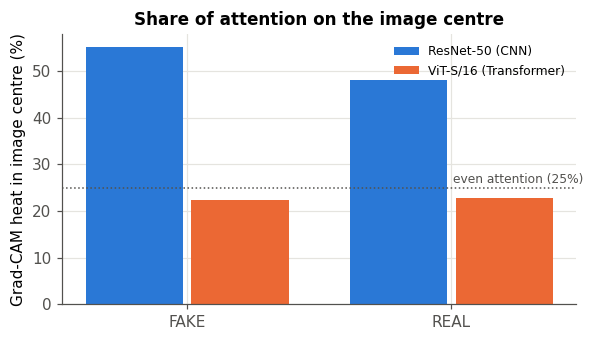

label                     FAKE       REAL
setup     model                          
trainSD14 resnet50   61.000000  47.000000
          vit_small  25.900000  20.100000
trainSD21 resnet50   49.299999  49.000000
          vit_small  18.600000  25.700001

In [ ]:
def center_share(cams, frac=0.5):
    """Fraction of heat inside the central square of side frac x width."""
    n, h, w = cams.shape
    ch, cw = int(h * frac), int(w * frac)
    top, left = (h - ch) // 2, (w - cw) // 2
    return cams[:, top:top + ch, left:left + cw].reshape(n, -1).sum(1) / (cams.reshape(n, -1).sum(1) + 1e-8)


rows = []
for (setup, m), model in models.items():
    for tname in ("test_sd14", "test_sd30"):
        x, y = test_sets[tname]
        for lab in (REAL, FAKE):
            pool = np.where(y == lab)[0]
            idx = rng.choice(pool, min(GRADCAM_IMAGES // 2, len(pool)), replace=False)
            cams, _ = gradcam(model, x[idx], target_class=lab)
            rows += [{"setup": setup, "model": m, "test_set": tname, "label": LABEL_NAMES[lab],
                      "center_share": v} for v in center_share(cams)]
attention = pd.DataFrame(rows)
attention.to_csv(RESULTS_DIR / "gradcam_center_share.csv", index=False)

means = attention.groupby(["model", "label"]).center_share.mean().unstack() * 100
fig, ax = plt.subplots(figsize=(5.5, 3.2))
width = 0.8 / len(means)
for k, (m, row) in enumerate(means.iterrows()):
    xs = np.arange(len(row)) + (k - (len(means) - 1) / 2) * width
    ax.bar(xs, row.values, width * 0.92, color=MODEL_COLORS[m], label=names[m])
ax.axhline(25, color=MUTED, ls=":", lw=1)
ax.text(len(means.columns) - 0.5, 26, "even attention (25%)", color=MUTED, ha="right", fontsize=8)
ax.set_xticks(range(len(means.columns)), means.columns)
ax.set(ylabel="Grad-CAM heat in image centre (%)", title="Share of attention on the image centre")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_gradcam_center_share.png")
plt.show()
(attention.groupby(["setup", "model", "label"]).center_share.mean().unstack() * 100).round(1)

**What this shows.** The CNN trained on SD 1.4 concentrates on the centre of the image, where the object usually is (61% of the heat for fakes, compared with 25% for an even spread). The ViTs spread their attention over the whole image (19 to 26%), including the background, which suggests they rely on image-wide statistics rather than the object itself.

## 8 · Score distributions

Accuracy depends on the 0.5 cut-off, but AUROC doesn't, and on new generators the two often disagree. These histograms show the P(fake) score each model gives to the real and fake test images. If the fake scores move to the left on a new generator but still sit to the right of the real scores, the model can still tell the two apart and only the cut-off is in the wrong place.

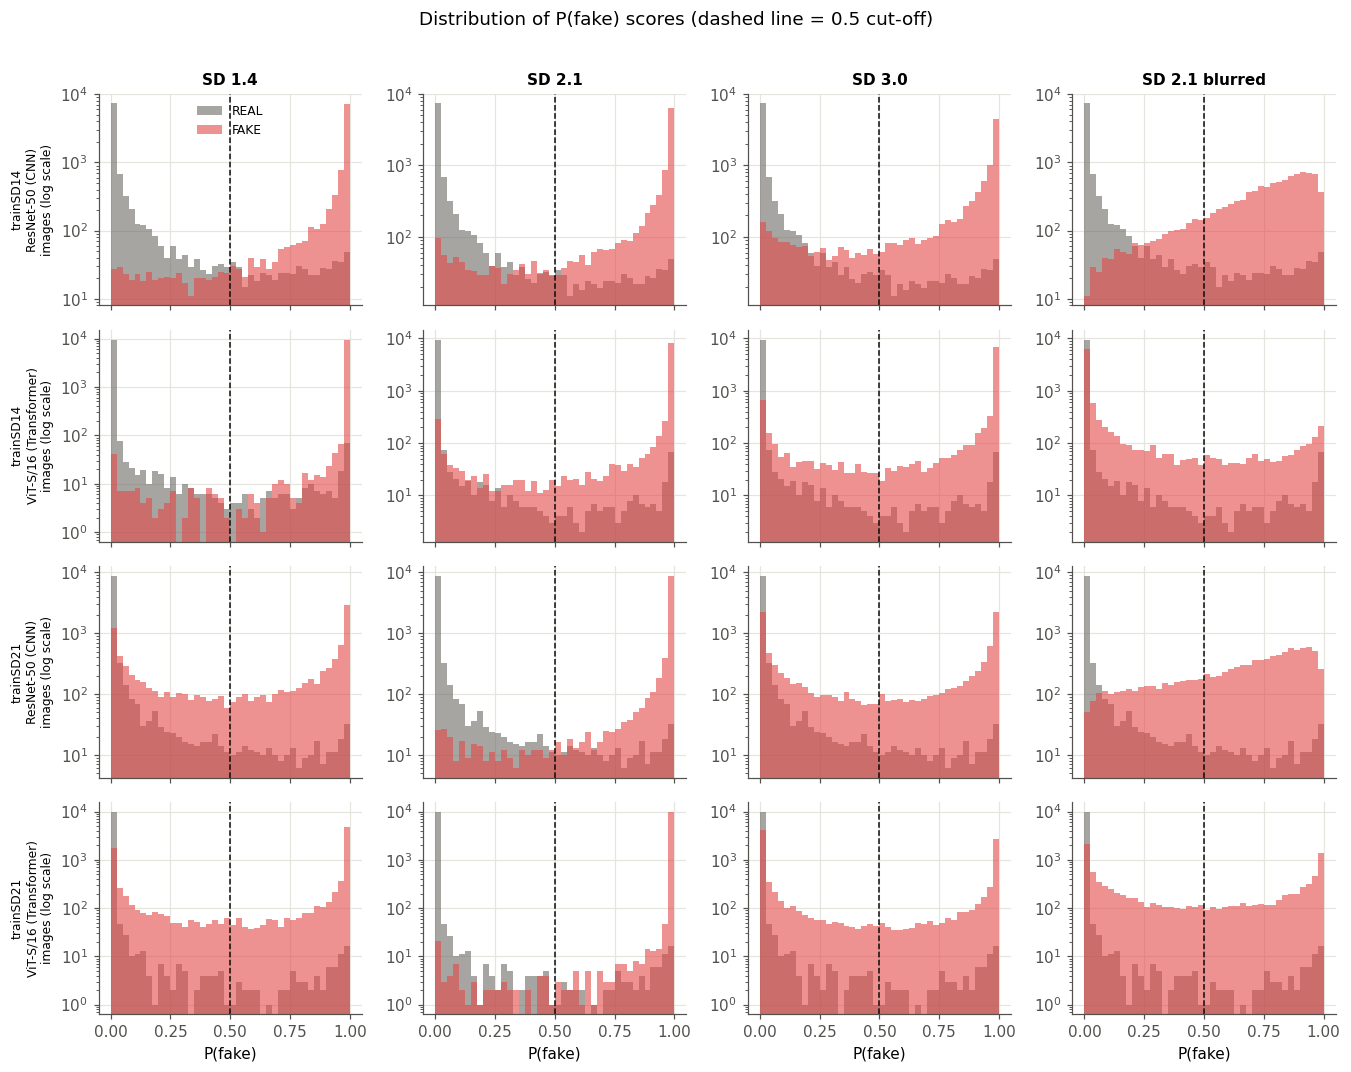

,setup,model,test_set,median P(fake) of fakes,% of fakes between 0.1 and 0.5,% of fakes below 0.1
0,trainSD14,ResNet-50 (CNN),test_sd14,0.995,3.313,0.993
1,trainSD14,ResNet-50 (CNN),test_sd21,0.990,5.440,2.490
2,trainSD14,ResNet-50 (CNN),test_sd30,0.962,10.200,4.580
3,trainSD14,ResNet-50 (CNN),test_sd21blur,0.793,13.400,1.040
4,trainSD14,ViT-S/16 (Transformer),test_sd14,1.000,0.699,0.638
5,trainSD14,ViT-S/16 (Transformer),test_sd21,1.000,2.850,4.190
6,trainSD14,ViT-S/16 (Transformer),test_sd30,0.999,5.950,9.590
7,trainSD14,ViT-S/16 (Transformer),test_sd21blur,0.005,12.050,74.580
8,trainSD21,ResNet-50 (CNN),test_sd14,0.801,16.646,21.560
9,trainSD21,ResNet-50 (CNN),test_sd21,0.998,1.760,0.810


In [ ]:
SCORE_COLORS = {REAL: "#6b6a63", FAKE: "#e34948"}
bins = np.linspace(0, 1, 41)

fig, axes = plt.subplots(len(models), len(TEST_SETS), figsize=(3.1 * len(TEST_SETS), 2.4 * len(models)),
                         sharex=True, squeeze=False)
for r, (setup, m) in enumerate(models):
    for c, tname in enumerate(TEST_SETS):
        ax = axes[r, c]
        y, p = test_sets[tname][1], probs[(setup, m, tname)]
        for lab in (REAL, FAKE):
            ax.hist(p[y == lab], bins=bins, color=SCORE_COLORS[lab], alpha=0.6, label=LABEL_NAMES[lab])
        ax.axvline(0.5, color=INK, ls="--", lw=1)
        ax.set_yscale("log")
        if r == 0:
            ax.set_title(TEST_SETS[tname], fontsize=10)
        if c == 0:
            ax.set_ylabel(f"{setup}\n{names[m]}\nimages (log scale)", fontsize=8)
        if r == len(models) - 1:
            ax.set_xlabel("P(fake)")
axes[0, 0].legend(fontsize=8, loc="upper center")
fig.suptitle("Distribution of P(fake) scores (dashed line = 0.5 cut-off)", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_score_distributions.png")
plt.show()

# Median score of the fake images, and share of fakes that land just under the cut-off
rows = []
for (setup, m) in models:
    for tname, (_, y) in test_sets.items():
        pf = probs[(setup, m, tname)][y == FAKE]
        rows.append({"setup": setup, "model": names[m], "test_set": tname,
                     "median P(fake) of fakes": np.median(pf),
                     "% of fakes between 0.1 and 0.5": ((pf >= 0.1) & (pf < 0.5)).mean() * 100,
                     "% of fakes below 0.1": (pf < 0.1).mean() * 100})
score_summary = pd.DataFrame(rows)
score_summary.to_csv(RESULTS_DIR / "score_summary.csv", index=False)
score_summary.round(3)

**What this shows.** On new generators, the fake scores of the ViT spread towards zero but many stay above the real scores, which is why its AUROC stays high while its accuracy drops. The ViT trained on SD 1.4 is a different case on the blurred set: three quarters of the blurred fakes get a score below 0.1 (median 0.005), so it is not just unsure but confidently wrong. The ViT trained on SD 2.1 shows the same pattern on SD 3.0 (median 0.12).

## 9 · Threshold recalibration

If the drop on new generators is mainly caused by the cut-off, it should be fixable without retraining. For each test set I take a small labelled sample (up to 100 real and 100 fake images), choose the cut-off that classifies that sample best, and then measure accuracy on the remaining images with both the default 0.5 cut-off and the new one. Results are averaged over the three seeds.

This simulates a realistic deployment situation: when a new generator appears, a platform can collect a few hundred labelled examples and re-tune its detector instead of retraining it.

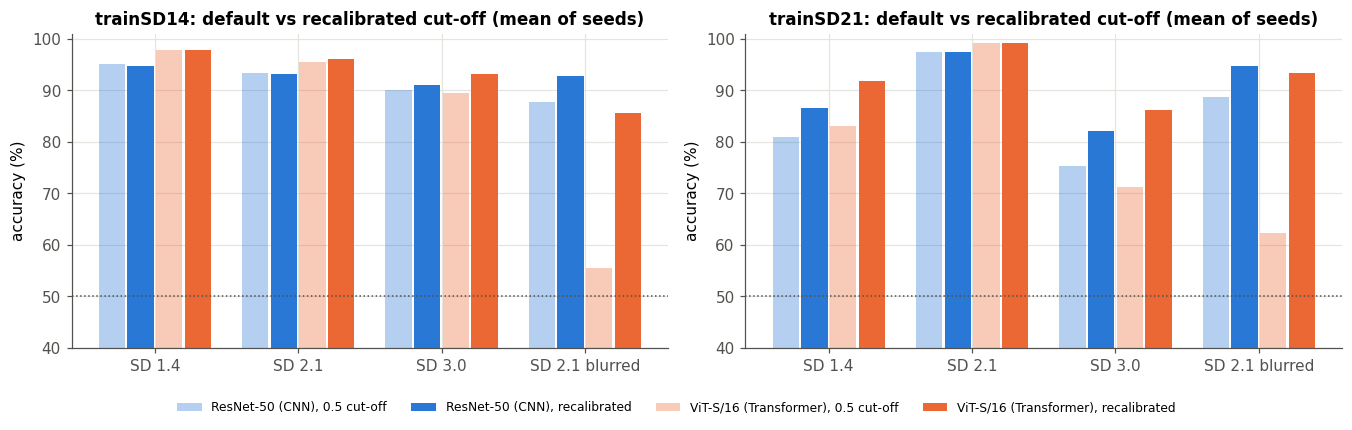

threshold  acc_default  \
setup     model                  test_set                                
trainSD14 ResNet-50 (CNN)        test_sd14          0.396       95.208   
          ViT-S/16 (Transformer) test_sd14          0.532       97.934   
trainSD21 ResNet-50 (CNN)        test_sd14          0.119       81.020   
          ViT-S/16 (Transformer) test_sd14          0.002       82.999   
trainSD14 ResNet-50 (CNN)        test_sd21          0.500       93.436   
          ViT-S/16 (Transformer) test_sd21          0.050       95.507   
trainSD21 ResNet-50 (CNN)        test_sd21          0.591       97.532   
          ViT-S/16 (Transformer) test_sd21          0.421       99.234   
trainSD14 ResNet-50 (CNN)        test_sd30          0.202       90.120   
          ViT-S/16 (Transformer) test_sd30          0.029       89.453   
trainSD21 ResNet-50 (CNN)        test_sd30          0.012       75.355   
          ViT-S/16 (Transformer) test_sd30          0.000       71.261   
trainSD14 ResNet-50 (CNN)        test_sd21blur      0.222       87.756   
          ViT-S/16 (Transformer) test_sd21blur      0.002       55.493   
trainSD21 ResNet-50 (CNN)        test_sd21blur      0.187       88.652   
          ViT-S/16 (Transformer) test_sd21blur      0.001       62.320   

                                                acc_recalibrated    gain  \
setup     model                  test_set                                  
trainSD14 ResNet-50 (CNN)        test_sd14                94.787  -0.420   
          ViT-S/16 (Transformer) test_sd14                97.878  -0.056   
trainSD21 ResNet-50 (CNN)        test_sd14                86.509   5.489   
          ViT-S/16 (Transformer) test_sd14                91.759   8.760   
trainSD14 ResNet-50 (CNN)        test_sd21                93.217  -0.219   
          ViT-S/16 (Transformer) test_sd21                96.116   0.609   
trainSD21 ResNet-50 (CNN)        test_sd21                97.471  -0.061   
          ViT-S/16 (Transformer) test_sd21                99.249   0.015   
trainSD14 ResNet-50 (CNN)        test_sd30                91.126   1.007   
          ViT-S/16 (Transformer) test_sd30                93.214   3.761   
trainSD21 ResNet-50 (CNN)        test_sd30                82.061   6.705   
          ViT-S/16 (Transformer) test_sd30                86.178  14.918   
trainSD14 ResNet-50 (CNN)        test_sd21blur            92.731   4.975   
          ViT-S/16 (Transformer) test_sd21blur            85.635  30.141   
trainSD21 ResNet-50 (CNN)        test_sd21blur            94.673   6.022   
          ViT-S/16 (Transformer) test_sd21blur            93.438  31.118   

                                                fake_acc_recalibrated  \
setup     model                  test_set                               
trainSD14 ResNet-50 (CNN)        test_sd14                     96.315   
          ViT-S/16 (Transformer) test_sd14                     97.564   
trainSD21 ResNet-50 (CNN)        test_sd14                     79.133   
          ViT-S/16 (Transformer) test_sd14                     88.175   
trainSD14 ResNet-50 (CNN)        test_sd21                     91.707   
          ViT-S/16 (Transformer) test_sd21                     97.677   
trainSD21 ResNet-50 (CNN)        test_sd21                     97.067   
          ViT-S/16 (Transformer) test_sd21                     99.232   
trainSD14 ResNet-50 (CNN)        test_sd30                     92.889   
          ViT-S/16 (Transformer) test_sd30                     93.616   
trainSD21 ResNet-50 (CNN)        test_sd30                     82.542   
          ViT-S/16 (Transformer) test_sd30                     82.768   
trainSD14 ResNet-50 (CNN)        test_sd21blur                 94.973   
          ViT-S/16 (Transformer) test_sd21blur                 89.532   
trainSD21 ResNet-50 (CNN)        test_sd21blur                 94.502   
          ViT-S/16 (Transformer) test_sd21blur                 93.953   

                               

In [ ]:
CALIB_PER_CLASS = 100
# Candidate cut-offs, dense near 0 and 1 because the scores cluster at the extremes
THRESHOLDS = np.unique(np.concatenate([np.logspace(-4, np.log10(0.5), 80),
                                       1 - np.logspace(np.log10(0.5), -4, 80)]))


def best_threshold(p, y):
    """Cut-off with the highest accuracy on the calibration sample (ties: closest to 0.5)."""
    accs = np.array([((p >= t) == y).mean() for t in THRESHOLDS])
    best = np.flatnonzero(accs == accs.max())
    return THRESHOLDS[best[np.argmin(np.abs(THRESHOLDS[best] - 0.5))]]


rows = []
for i, (tname, (_, y)) in enumerate(test_sets.items()):
    # The same calibration images are used for every model, so the comparison stays fair
    cal_rng = np.random.default_rng(SEED + i)
    cal = np.concatenate([cal_rng.choice(np.where(y == lab)[0], min(CALIB_PER_CLASS, (y == lab).sum() // 2),
                                         replace=False) for lab in (REAL, FAKE)])
    rest = np.setdiff1d(np.arange(len(y)), cal)
    for run in runs:
        setup, m, seed, aug = run
        p = P[(run, tname)]
        t = best_threshold(p[cal], y[cal])
        row = {"setup": setup, "model": m, "seed": seed, "augment": aug, "test_set": tname, "threshold": t}
        for name, cut in (("default", 0.5), ("recalibrated", t)):
            pred = p[rest] >= cut
            row[f"acc_{name}"] = (pred == y[rest]).mean() * 100
            row[f"fake_acc_{name}"] = pred[y[rest] == FAKE].mean() * 100
            row[f"real_acc_{name}"] = (~pred[y[rest] == REAL]).mean() * 100
        rows.append(row)
recal_all = pd.DataFrame(rows)
recal_all["gain"] = recal_all.acc_recalibrated - recal_all.acc_default
recal_all.to_csv(RESULTS_DIR / "threshold_recalibration_all_runs.csv", index=False)
recal = (recal_all[~recal_all.augment]
         .groupby(["setup", "model", "test_set"], sort=False)
         [["threshold", "acc_default", "acc_recalibrated", "gain", "fake_acc_recalibrated", "real_acc_recalibrated"]]
         .mean().reset_index())
recal.to_csv(RESULTS_DIR / "threshold_recalibration.csv", index=False)

fig, axes = plt.subplots(1, len(TRAIN_SETUPS), figsize=(6.2 * len(TRAIN_SETUPS), 3.6), squeeze=False)
width = 0.2
for ax, setup in zip(axes[0], TRAIN_SETUPS):
    d = recal[recal.setup == setup].set_index(["model", "test_set"])
    for k, m in enumerate(MODELS):
        for j, (kind, alpha) in enumerate((("default", 0.35), ("recalibrated", 1.0))):
            xs = np.arange(len(TEST_SETS)) + (2 * k + j - 1.5) * width
            vals = [d.loc[(m, t), f"acc_{kind}"] for t in TEST_SETS]
            ax.bar(xs, vals, width * 0.92, color=MODEL_COLORS[m], alpha=alpha,
                   label=f"{names[m]}, {'0.5 cut-off' if kind == 'default' else 'recalibrated'}")
    ax.axhline(50, color=MUTED, ls=":", lw=1)
    ax.set_xticks(range(len(TEST_SETS)), [TEST_SETS[t] for t in TEST_SETS])
    ax.set(ylim=(40, 101), ylabel="accuracy (%)", title=f"{setup}: default vs recalibrated cut-off (mean of seeds)")
fig.tight_layout()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
fig.savefig(FIG_DIR / "03_threshold_recalibration.png")
plt.show()

recal.assign(model=recal.model.map(names)).set_index(["setup", "model", "test_set"]).round(3)

**What this shows.** Re-setting the cut-off with only 100 real and 100 fake labelled images recovers most of the lost accuracy, and the ViT gains much more than the CNN. After recalibration the ViT is better than the CNN on all four unseen-generator tests, for example 86.2% vs 82.1% on SD 3.0 after SD 2.1 training (up from 71.3%), and 93.2% vs 91.1% on SD 3.0 after SD 1.4 training. On the blurred set the ViT gains about 30 points (to 85.6% and 93.4%), but the CNN is still better (92.7% and 94.7%). This confirms that most of the ViT's errors on new generators come from the threshold rather than from losing the ability to separate real and fake images.

## 10 · Detection rate by object class

Jiang's fake images are stored by CIFAR-10 class (airplane, car, bird, ...), so it's possible to check whether some kinds of object are harder to catch than others. CIFAKE's own files don't record the class, so this covers the SD 2.1, SD 3.0 and blurred SD 2.1 fakes only. Each cell is the percentage of fakes of that class that the model detected, averaged over the three seeds.

/tmp/ipykernel_1557/1818329232.py:1: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  manifest = pd.read_csv(DATA_DIR / "manifest.csv")


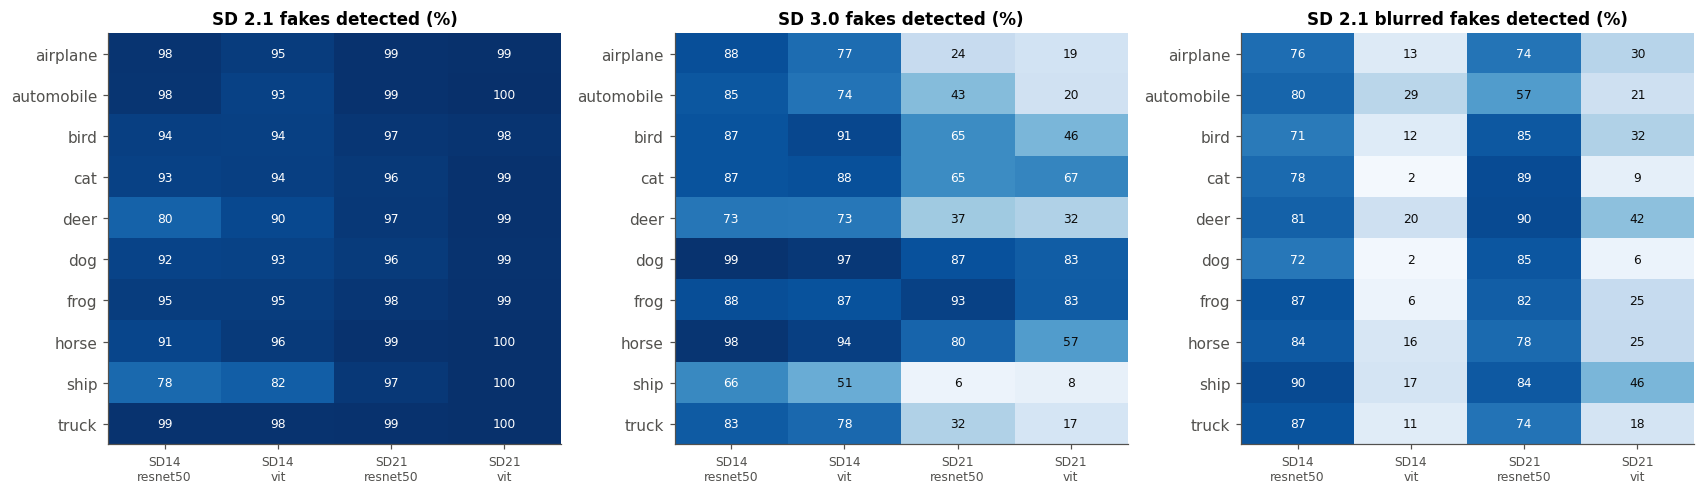

,setup,model,hardest class,hardest %,easiest class,easiest %
0,trainSD14,ResNet-50 (CNN),ship,65.8,dog,98.6
1,trainSD14,ViT-S/16 (Transformer),ship,50.6,dog,96.7
2,trainSD21,ResNet-50 (CNN),ship,5.7,frog,93.3
3,trainSD21,ViT-S/16 (Transformer),ship,8.1,frog,83.0


In [ ]:
manifest = pd.read_csv(DATA_DIR / "manifest.csv")
class_sets = ["test_sd21", "test_sd30", "test_sd21blur"]
rows = []
for tname in class_sets:
    y = test_sets[tname][1]
    cls = manifest[manifest.split == tname].cls.to_numpy()
    assert len(cls) == len(y), "manifest and saved split are out of sync"
    fake = (y == FAKE) & (cls != "unknown")
    for run in [r for r in runs if not r[3]]:
        setup, m, seed, _ = run
        caught = P[(run, tname)] >= 0.5
        for c in sorted(set(cls[fake])):
            sel = fake & (cls == c)
            rows.append({"setup": setup, "model": m, "seed": seed, "test_set": tname, "class": c,
                         "n": int(sel.sum()), "fake_acc": caught[sel].mean() * 100})
per_class_all = pd.DataFrame(rows)
per_class_all.to_csv(RESULTS_DIR / "per_class_fake_accuracy_all_runs.csv", index=False)
per_class = per_class_all.groupby(["setup", "model", "test_set", "class"], sort=False)[["n", "fake_acc"]].mean().reset_index()
per_class.to_csv(RESULTS_DIR / "per_class_fake_accuracy.csv", index=False)

fig, axes = plt.subplots(1, len(class_sets), figsize=(5.2 * len(class_sets), 4.6), squeeze=False)
for ax, tname in zip(axes[0], class_sets):
    t = per_class[per_class.test_set == tname].pivot_table(index="class", columns=["setup", "model"],
                                                         values="fake_acc")
    ax.imshow(t.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(t.shape[1]), [f"{s.replace('train', '')}\n{m.split('_')[0]}" for s, m in t.columns],
                  fontsize=8)
    ax.set_yticks(range(t.shape[0]), t.index)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else INK)
    ax.set_title(f"{TEST_SETS[tname]} fakes detected (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_per_class_fake_accuracy.png")
plt.show()

# Easiest and hardest classes for each model on the unseen SD 3.0 generator
rows = []
for (setup, m), g in per_class[per_class.test_set == "test_sd30"].groupby(["setup", "model"], sort=False):
    lo, hi = g.loc[g.fake_acc.idxmin()], g.loc[g.fake_acc.idxmax()]
    rows.append({"setup": setup, "model": names[m], "hardest class": lo["class"], "hardest %": lo.fake_acc,
                 "easiest class": hi["class"], "easiest %": hi.fake_acc})
pd.DataFrame(rows).round(1)

**What this shows.** Ships are the hardest class to detect on SD 3.0 for every model (only 6 to 8% caught after SD 2.1 training), while dogs and frogs are the easiest. Detection rates therefore depend on the content of the image, not only on the generator, which is a bias a real deployment would need to check.

## 11 · Most confident mistakes

The images each seed-42 model got wrong with the highest confidence, for the models trained on SD 1.4 and tested on the unseen SD 3.0 generator. The top row of each pair shows fakes the model was most sure were real; the bottom row shows real photographs it was most sure were fake. The number above each image is P(fake).

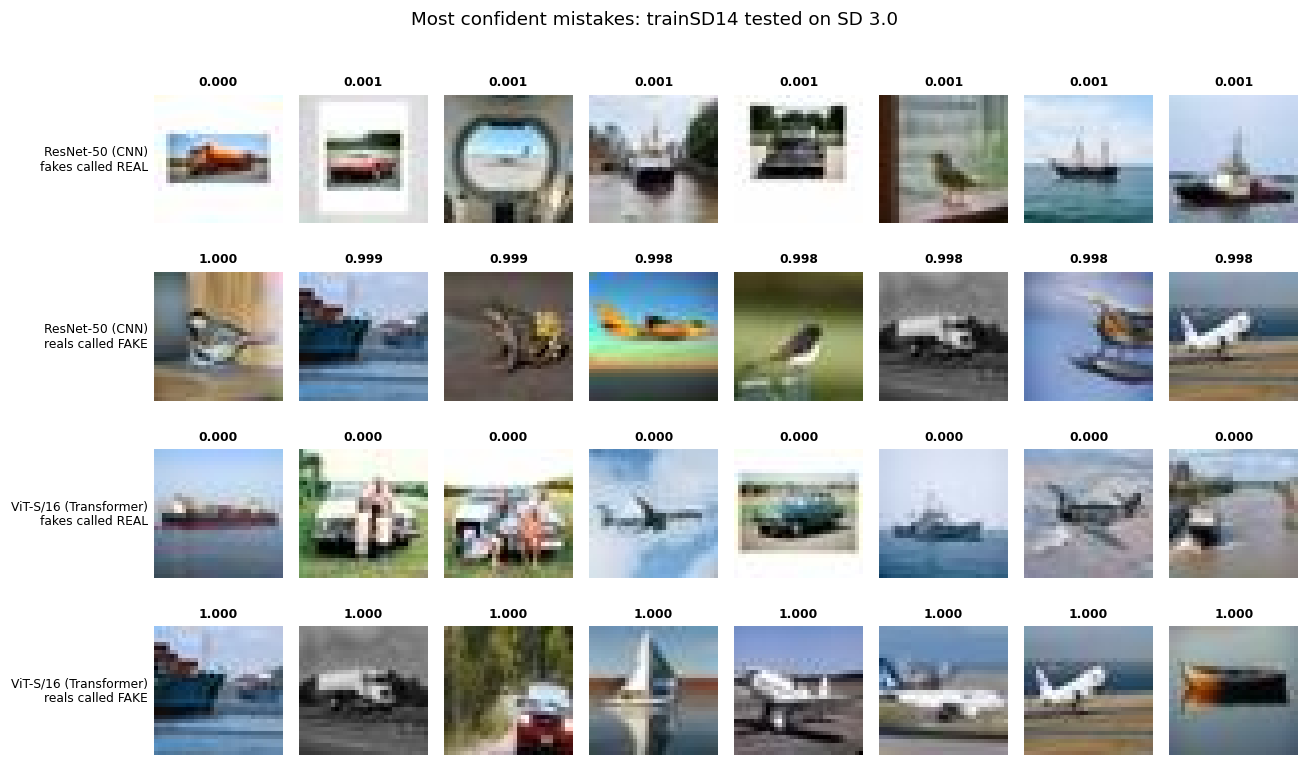

In [ ]:
N_SHOW = 8
setup, tname = "trainSD14", "test_sd30"
x, y = test_sets[tname]
fig, axes = plt.subplots(2 * len(MODELS), N_SHOW, figsize=(1.5 * N_SHOW, 1.75 * 2 * len(MODELS)), squeeze=False)
for k, m in enumerate(MODELS):
    p = probs[(setup, m, tname)]
    missed = np.where((y == FAKE) & (p < 0.5))[0]
    missed = missed[np.argsort(p[missed])][:N_SHOW]
    accused = np.where((y == REAL) & (p >= 0.5))[0]
    accused = accused[np.argsort(-p[accused])][:N_SHOW]
    for r, (idx, label) in enumerate(((missed, "fakes called REAL"), (accused, "reals called FAKE"))):
        row = 2 * k + r
        for j in range(N_SHOW):
            ax = axes[row, j]
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(False)
            if j < len(idx):
                ax.imshow(x[idx[j]])
                ax.set_title(f"{p[idx[j]]:.3f}", fontsize=8)
            elif j == 0:
                ax.text(0.5, 0.5, "no mistakes of this kind", ha="center", va="center", fontsize=8,
                        color=MUTED, transform=ax.transAxes)
        axes[row, 0].set_ylabel(f"{names[m]}\n{label}", fontsize=8, rotation=0, ha="right", va="center")
fig.suptitle(f"Most confident mistakes: {setup} tested on {TEST_SETS[tname]}", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_confident_mistakes.png")
plt.show()

**What this shows.** Many of the most confident mistakes are ships and aeroplanes against plain sky or water, and some fakes look like a photo with a border. The ViT's mistakes have scores of exactly 0.000 or 1.000, so when it is wrong it is wrong with full confidence, which matters if a score is shown to users as a measure of certainty.

## 12 · Summary of key results

In [17]:
def stat(setup, model, test_set, col="accuracy"):
    sel = (metrics_mean.setup == setup) & (metrics_mean.model == model) & (metrics_mean.test_set == test_set)
    sd = metrics_std.loc[(metrics_std.setup == setup) & (metrics_std.model == model)
                         & (metrics_std.test_set == test_set), col].item()
    return metrics_mean.loc[sel, col].item(), (0.0 if sd != sd else sd)


lines = ["### Key results (mean \u00b1 sd across seeds)\n"]
for setup in TRAIN_SETUPS:
    lines.append(f"**{setup}**\n")
    for t in TEST_SETS:
        (a, sa), (b, sb) = stat(setup, cnn, t), stat(setup, vit, t)
        c = consistency.loc[(setup, t)]
        lines.append(f"- {TEST_SETS[t]}: CNN {a:.2f} \u00b1 {sa:.2f}% vs ViT {b:.2f} \u00b1 {sb:.2f}% "
                     f"(ViT {b - a:+.2f} points; ViT better in {c.ViT_better_in}/{c.seeds} seeds, "
                     f"significant in {c.significant_in}/{c.seeds})")
    home = in_domain[setup]
    for m in MODELS:
        drop = stat(setup, m, home)[0] - stat(setup, m, "test_sd30")[0]
        lines.append(f"- {names[m]}: accuracy drop from in-domain to SD 3.0 = {drop:.2f} points")
    if aug_runs:
        for m in MODELS:
            d = augmentation[(augmentation.setup == setup) & (augmentation.model == m)].set_index("test_set")
            if len(d):
                lines.append(f"- {names[m]} with augmentation: blurred {d.loc['test_sd21blur', 'acc_augmented']:.2f}% "
                             f"({d.loc['test_sd21blur', 'change']:+.2f}), SD 3.0 {d.loc['test_sd30', 'acc_augmented']:.2f}% "
                             f"({d.loc['test_sd30', 'change']:+.2f}), in-domain {d.loc[home, 'acc_augmented']:.2f}% "
                             f"({d.loc[home, 'change']:+.2f})")
    lines.append("")
summary_text = "\n".join(lines)
(RESULTS_DIR / "key_results.md").write_text(summary_text)
display(Markdown(summary_text))

### Key results (mean ± sd across seeds)

**trainSD14**

- SD 1.4: CNN 95.19 ± 0.04% vs ViT 97.94 ± 0.80% (ViT +2.75 points; ViT better in 3.0/3.0 seeds, significant in 3.0/3.0)
- SD 2.1: CNN 93.44 ± 0.05% vs ViT 95.51 ± 0.29% (ViT +2.07 points; ViT better in 3.0/3.0 seeds, significant in 3.0/3.0)
- SD 3.0: CNN 90.12 ± 0.35% vs ViT 89.44 ± 1.78% (ViT -0.69 points; ViT better in 1.0/3.0 seeds, significant in 3.0/3.0)
- SD 2.1 blurred: CNN 87.75 ± 3.76% vs ViT 55.46 ± 5.30% (ViT -32.29 points; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0)
- ResNet-50 (CNN): accuracy drop from in-domain to SD 3.0 = 5.07 points
- ViT-S/16 (Transformer): accuracy drop from in-domain to SD 3.0 = 8.50 points
- ResNet-50 (CNN) with augmentation: blurred 77.08% (-10.67), SD 3.0 85.81% (-4.31), in-domain 93.61% (-1.58)
- ViT-S/16 (Transformer) with augmentation: blurred 79.97% (+24.52), SD 3.0 86.69% (-2.74), in-domain 98.05% (+0.11)

**trainSD21**

- SD 1.4: CNN 81.01 ± 1.05% vs ViT 83.00 ± 1.65% (ViT +1.99 points; ViT better in 2.0/3.0 seeds, significant in 2.0/3.0)
- SD 2.1: CNN 97.54 ± 0.11% vs ViT 99.24 ± 0.06% (ViT +1.70 points; ViT better in 3.0/3.0 seeds, significant in 3.0/3.0)
- SD 3.0: CNN 75.34 ± 0.97% vs ViT 71.25 ± 1.51% (ViT -4.09 points; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0)
- SD 2.1 blurred: CNN 88.63 ± 3.09% vs ViT 62.31 ± 8.81% (ViT -26.32 points; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0)
- ResNet-50 (CNN): accuracy drop from in-domain to SD 3.0 = 22.19 points
- ViT-S/16 (Transformer): accuracy drop from in-domain to SD 3.0 = 27.99 points
- ResNet-50 (CNN) with augmentation: blurred 90.54% (+1.91), SD 3.0 70.36% (-4.98), in-domain 96.16% (-1.38)
- ViT-S/16 (Transformer) with augmentation: blurred 95.75% (+33.44), SD 3.0 65.16% (-6.09), in-domain 98.97% (-0.27)
